# T3 — Experimentos II
**Autor:** Noel Roldán Manzanares  
**Proyecto P2:** Auditar e integrar un detector de intrusiones con IA

> Hipótesis conservadas antes de la ejecución. Datos comunes generados con semilla 21.

> **Completado por Daniel Schwab (jefe de grupo) el 31/10/2026:** ejecución del cuaderno, resultados y explicaciones de E4–E7, comprobación de las IPs mal clasificadas, tabla de registro, P13 y sección 8. Las hipótesis son las de Noel y no se han modificado.

## Base común (todos)
> **No la modifiquéis.** Este cuaderno está en `Proyecto2/notebooks/`, pero `logtools.py` y los datos (`auth.log`, `etiquetas.csv`) están en `Proyecto2/`. Esta celda hace que el cuaderno trabaje desde esa carpeta, para que todo funcione igual que en el cuaderno original del kit.

In [1]:
# --- BASE COMÚN (no modificar) ---
import os
import sys
from pathlib import Path

# Si el cuaderno se abre desde notebooks/, subimos a la carpeta Proyecto2/.
# Se comprueba antes para que ejecutar la celda dos veces no suba dos carpetas.
if Path.cwd().name == "notebooks":
    os.chdir("..")

# Así Python encuentra logtools.py al hacer el import.
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

print("Carpeta de trabajo:", os.getcwd())
print("¿Está auth.log?", Path("auth.log").exists())

Carpeta de trabajo: /home/claude/proyectospython/Proyecto2
¿Está auth.log? True


# Proyecto DAM — Cuaderno de análisis del detector de intrusiones

Este cuaderno **ya está escrito**: tu trabajo no es programarlo, sino **entenderlo, ponerlo a prueba y criticarlo**.

**Cómo usarlo**

1. Antes de empezar, genera tus datos en la terminal (usa tu número de lista como semilla):
   `python generar_logs.py --seed <tu_numero> --salida auth.log --etiquetas etiquetas.csv`
2. Ejecuta las celdas **en orden** (Mayús + Intro).
3. Las celdas marcadas con ❓ son preguntas: escribe tu respuesta en la celda de texto que hay debajo (doble clic para editarla).
4. Las celdas marcadas con 🧪 son experimentos: cambia **solo** el valor indicado, ejecuta y anota el resultado en la tabla final.

## 0. Preparación

In [2]:
# Generamos los datos comunes del grupo con la semilla 21
import subprocess, sys
subprocess.run([sys.executable, "generar_logs.py", "--seed", "21", "--salida", "auth.log", "--etiquetas", "etiquetas.csv"], check=True)

12425 lineas en auth.log; 384 IPs (100 atacantes) en etiquetas.csv


CompletedProcess(args=['/usr/bin/python3', 'generar_logs.py', '--seed', '21', '--salida', 'auth.log', '--etiquetas', 'etiquetas.csv'], returncode=0)

In [3]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from logtools import cargar_etiquetas, cargar_log, construir_features

RUTA_LOG = "auth.log"
RUTA_ETIQUETAS = "etiquetas.csv"

## 1. Del texto del log a una tabla

La función `cargar_log` (en `logtools.py`) lee cada línea del fichero, extrae sus datos con expresiones regulares y los guarda en un `DataFrame`.

In [4]:
df = cargar_log(RUTA_LOG)
df.head(10)

12425 eventos cargados; 0 lineas ignoradas


,timestamp,tipo,usuario,ip,puerto,usuario_invalido
0,2026-10-07 00:00:00,acceso_ok,backup,10.0.0.5,43662,False
1,2026-10-07 00:05:25,usuario_invalido,mysql,203.0.113.226,44570,True
2,2026-10-07 00:05:25,fallo_password,mysql,203.0.113.226,44570,True
3,2026-10-07 00:06:56,fallo_password,root,198.51.100.131,53992,False
4,2026-10-07 00:07:46,usuario_invalido,git,203.0.113.15,58764,True
5,2026-10-07 00:07:46,fallo_password,git,203.0.113.15,58764,True
6,2026-10-07 00:08:59,usuario_invalido,test,203.0.113.122,58091,True
7,2026-10-07 00:08:59,fallo_password,test,203.0.113.122,58091,True
8,2026-10-07 00:09:01,usuario_invalido,guest,203.0.113.122,41748,True
9,2026-10-07 00:09:01,fallo_password,guest,203.0.113.122,41748,True


In [5]:
df["tipo"].value_counts()

tipo
fallo_password      5972
usuario_invalido    4883
conexion_cerrada     905
acceso_ok            665
Name: count, dtype: int64

❓ **P1.** ¿Qué representa cada fila de `df`? ¿Qué columnas tiene y qué significa cada una?

*Respondida en T1 (`T1_comprender.ipynb`) y en el cuaderno final (`P2_analisis_intrusiones.ipynb`).*

❓ **P2.** Abre `logtools.py` y localiza `PATRON_LINEA`. Explica con tus palabras qué trozo de la línea captura cada parte con nombre (`mes`, `dia`, `hora`, `host`, `pid`, `msg`).

*Respondida en T1 (`T1_comprender.ipynb`) y en el cuaderno final (`P2_analisis_intrusiones.ipynb`).*

❓ **P3.** El log de syslog no trae el año. ¿Cómo lo resuelve el código y qué problema podría dar con un log que cruce el 31 de diciembre?

*Respondida en T1 (`T1_comprender.ipynb`) y en el cuaderno final (`P2_analisis_intrusiones.ipynb`).*

## 2. Características por IP

Un modelo de IA no entiende líneas de texto: necesita **una fila de números por cada cosa que queremos clasificar**. Aquí clasificamos direcciones IP, así que `construir_features` resume lo que ha hecho cada IP.

In [6]:
X = construir_features(df)
X.head()

,n_eventos,n_fallos,n_ok,n_usuarios,n_inv,duracion_min,ratio_fallos,fallos_por_min,es_interna,max_fallos_5min,hora_media
ip,,,,,,,,,,,
10.0.0.5,24,0,24,1,0,1383.000000,0.0,0.000000,1,0,11.5
10.0.1.1,1,0,1,1,0,0.000000,0.0,0.000000,1,0,11.0
10.0.1.10,4,2,2,1,0,247.900000,0.5,0.008068,1,2,13.0
10.0.1.11,3,3,0,1,0,0.416667,1.0,3.000000,1,3,7.0
10.0.1.12,5,1,4,1,0,384.483333,0.2,0.002601,1,1,11.6


In [7]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
n_eventos,384.0,32.356771,89.313192,1.0,3.000000,5.000000,11.000000,543.0
n_fallos,384.0,15.552083,40.768177,0.0,0.000000,2.000000,8.000000,247.0
n_ok,384.0,1.731771,1.775502,0.0,1.000000,1.000000,3.000000,24.0
n_usuarios,384.0,2.703125,3.621143,1.0,1.000000,1.000000,1.000000,12.0
n_inv,384.0,25.432292,82.311264,0.0,0.000000,0.000000,0.000000,494.0
duracion_min,384.0,276.152300,364.872045,0.0,1.404167,170.816667,384.991667,1407.9
ratio_fallos,384.0,0.385966,0.333321,0.0,0.000000,0.444444,0.578571,1.0
fallos_por_min,384.0,4.267150,11.823057,0.0,0.000000,0.007208,0.143926,55.0
es_interna,384.0,0.687500,0.464117,0.0,0.000000,1.000000,1.000000,1.0
max_fallos_5min,384.0,12.604167,37.923650,0.0,0.000000,1.000000,3.000000,213.0


❓ **P4.** ¿Qué representa ahora cada fila? ¿Por qué se agrupa por IP y no por usuario o por evento?

*Respondida en T1 (`T1_comprender.ipynb`) y en el cuaderno final (`P2_analisis_intrusiones.ipynb`).*

❓ **P5.** Antes de mirar los resultados del modelo, elige **tres características** que creas que mejor distinguen a un atacante de un usuario normal y justifica por qué.

*Respondida en T1 (`T1_comprender.ipynb`) y en el cuaderno final (`P2_analisis_intrusiones.ipynb`).*

## 3. ¿Cuántos atacantes hay y en qué se diferencian?

In [8]:
y = cargar_etiquetas(RUTA_ETIQUETAS, X.index)
print(y.value_counts().rename({0: "legítimas", 1: "atacantes"}))
print(f"Proporción de atacantes: {y.mean():.0%}")

etiqueta
legítimas    284
atacantes    100
Name: count, dtype: int64
Proporción de atacantes: 26%


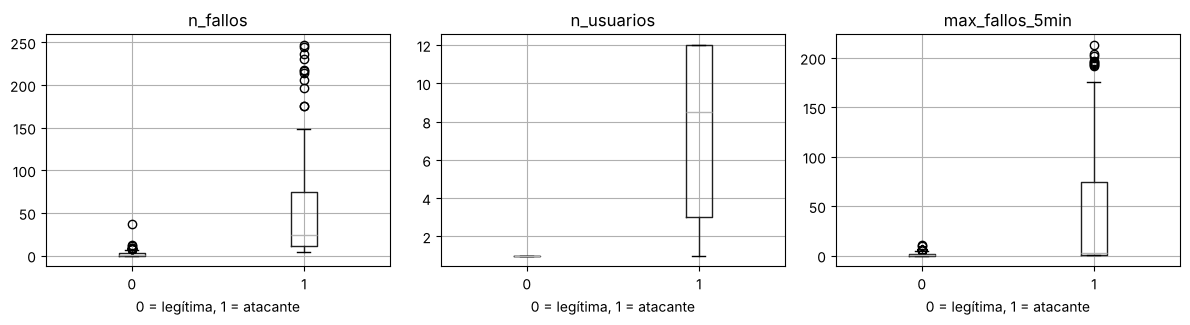

In [9]:
fig, ejes = plt.subplots(1, 3, figsize=(12, 3.5))
for eje, col in zip(ejes, ["n_fallos", "n_usuarios", "max_fallos_5min"]):
    X.assign(etiqueta=y).boxplot(column=col, by="etiqueta", ax=eje)
    eje.set_title(col)
    eje.set_xlabel("0 = legítima, 1 = atacante")
plt.suptitle("")
plt.tight_layout()
plt.show()

❓ **P6.** ¿Coinciden las tres características que elegiste en P5 con lo que ves en los gráficos? ¿Alguna te ha sorprendido?

*Respondida en T1 (`T1_comprender.ipynb`) y en el cuaderno final (`P2_analisis_intrusiones.ipynb`).*

❓ **P7.** Hay IPs legítimas con muchos fallos y atacantes con pocos. Localiza al menos un caso de cada tipo en `X` (pista: `X[(y == 0) & (X["n_fallos"] > 10)]`) y explica por qué engañan a una regla sencilla.

*Respondida en T1 (`T1_comprender.ipynb`) y en el cuaderno final (`P2_analisis_intrusiones.ipynb`).*

## 4. Entrenar y evaluar el modelo

Se reserva un 25 % de las IPs para **examinar** el modelo con datos que no ha visto durante el entrenamiento.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

modelo = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
modelo.fit(X_train, y_train)

pred = modelo.predict(X_test)
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, digits=3))

[[71  0]
 [ 0 25]]
              precision    recall  f1-score   support

           0      1.000     1.000     1.000        71
           1      1.000     1.000     1.000        25

    accuracy                          1.000        96
   macro avg      1.000     1.000     1.000        96
weighted avg      1.000     1.000     1.000        96



❓ **P8.** Lee la matriz de confusión: ¿cuántos usuarios legítimos habrían sido bloqueados por error (falsos positivos)? ¿Y cuántos atacantes se han colado (falsos negativos)? ¿Qué error es más grave en un servidor real y por qué?

*Respondida en T1 (`T1_comprender.ipynb`) y en el cuaderno final (`P2_analisis_intrusiones.ipynb`).*

❓ **P9.** ¿Qué hacen `stratify=y` y `class_weight="balanced"`? ¿Qué pasaría sin ellos?

*Respondida en T1 (`T1_comprender.ipynb`) y en el cuaderno final (`P2_analisis_intrusiones.ipynb`).*

❓ **P10.** ¿Por qué se evalúa con IPs que el modelo no ha visto al entrenar? ¿Qué podría ocurrir si evaluáramos con las mismas?

*Respondida en T1 (`T1_comprender.ipynb`) y en el cuaderno final (`P2_analisis_intrusiones.ipynb`).*

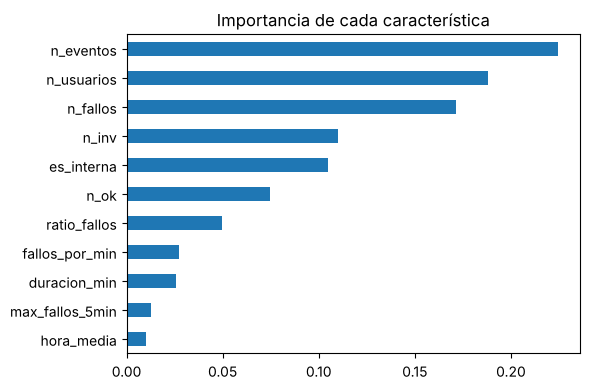

In [11]:
importancias = pd.Series(modelo.feature_importances_, index=X.columns).sort_values()
importancias.plot.barh(figsize=(6, 4), title="Importancia de cada característica")
plt.tight_layout()
plt.show()

❓ **P11.** ¿Qué dos características pesan más? ¿Tiene sentido desde el punto de vista de un administrador? ¿Hay alguna que te haga sospechar (pista: ¿qué pasa si una característica solo existe cuando el ataque ya ha tenido éxito)?

*Respondida en T1 (`T1_comprender.ipynb`) y en el cuaderno final (`P2_analisis_intrusiones.ipynb`).*

## 5. Herramientas para experimentar

Estas funciones ya están hechas. Las usarás en los experimentos de la sección 6: **no hace falta modificarlas**.

In [12]:
def evaluar_xy(X, y, umbral=0.5, quitar=(), semilla=42, mostrar=True):
    """Entrena un modelo nuevo y lo evalúa. Devuelve (precisión, recall, F1) de la clase 'atacante'.

    umbral : probabilidad mínima para marcar una IP como atacante.
    quitar : lista de características que NO se le darán al modelo.
    semilla: controla qué IPs caen en entrenamiento y cuáles en prueba.
    """
    cols = [c for c in X.columns if c not in quitar]
    X_tr, X_te, y_tr, y_te = train_test_split(
        X[cols], y, test_size=0.25, stratify=y, random_state=semilla)
    m = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
    m.fit(X_tr, y_tr)
    pred = (m.predict_proba(X_te)[:, 1] >= umbral).astype(int)
    p = precision_score(y_te, pred, zero_division=0)
    r = recall_score(y_te, pred, zero_division=0)
    f = f1_score(y_te, pred, zero_division=0)
    if mostrar:
        tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
        print(f"precisión={p:.3f}  recall={r:.3f}  F1={f:.3f}   "
              f"(bloqueos injustos={fp}, atacantes que se cuelan={fn})")
    return p, r, f

In [13]:
evaluar_xy(X, y)   # resultado de referencia, sin tocar nada

precisión=1.000  recall=1.000  F1=1.000   (bloqueos injustos=0, atacantes que se cuelan=0)


(1.0, 1.0, 1.0)

## 6. 🧪 Experimentos

Para cada experimento, **antes de ejecutar** escribe en la tabla final tu **hipótesis** (¿qué crees que pasará y por qué?). Después ejecuta, anota el resultado y **explica** si coincidió con lo que esperabas.

Haz **al menos 5 de los 7**, incluyendo siempre E1 y E2.

### 🧪 E4 — ¿Cuánto depende el resultado de la suerte del reparto?

**Hipótesis (escrita antes de ejecutar):** creo que el resultado será bastante parecido aunque cambie la semilla del reparto, porque el modelo utiliza las mismas características y los datos mantienen una estructura similar.

**Cambio:** únicamente cambio la semilla utilizada para separar los datos de entrenamiento y prueba.

In [14]:
resultados = [evaluar_xy(X, y, semilla=s, mostrar=False)[2] for s in range(10)]
print("F1 en 10 repartos:", [round(r, 3) for r in resultados])
print(f"media={pd.Series(resultados).mean():.3f}  mínimo={min(resultados):.3f}  máximo={max(resultados):.3f}")

F1 en 10 repartos: [1.0, 1.0, 0.98, 0.98, 0.98, 1.0, 0.96, 0.98, 1.0, 0.958]
media=0.984  mínimo=0.958  máximo=1.000


**Comprobación añadida (Daniel):** ¿qué IPs clasifica mal el modelo en cada reparto? Usa el mismo reparto y el mismo modelo que `evaluar_xy`, con umbral 0.5. Debajo se muestran las características de las IPs que fallan.

In [15]:
# Comprobación añadida por Daniel: ¿qué IPs se clasifican mal en cada reparto?
# Mismo reparto y mismo modelo que evaluar_xy (umbral 0.5).
def ips_mal_clasificadas(X, y, semillas=range(10), umbral=0.5):
    for s in semillas:
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=0.25, stratify=y, random_state=s)
        m = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
        m.fit(X_tr, y_tr)
        prob = pd.Series(m.predict_proba(X_te)[:, 1], index=X_te.index)
        mal = prob[(prob >= umbral).astype(int) != y_te]   # IPs mal clasificadas
        if mal.empty:
            print(f"reparto {s}: ningún error")
        else:
            print(f"reparto {s}: " + ", ".join(
                f"{ip} ({'atacante' if y_te[ip] == 1 else 'legítima'}, prob. {p:.2f})"
                for ip, p in mal.items()))

ips_mal_clasificadas(X, y)
# ¿En qué repartos caen en la prueba las IPs que fallan? (el reparto 42 es el del resto del cuaderno)
for ip in ["192.168.1.249", "198.51.100.26", "203.0.113.86"]:
    en_prueba = [s for s in list(range(10)) + [42]
                 if ip in train_test_split(X, y, test_size=0.25, stratify=y, random_state=s)[1].index]
    print(f"{ip} cae en la prueba en los repartos {en_prueba}")
X.loc[["192.168.1.249", "198.51.100.26", "203.0.113.86"]].round(2)

reparto 0: ningún error


reparto 1: ningún error


reparto 2: 198.51.100.26 (atacante, prob. 0.41)


reparto 3: 192.168.1.249 (legítima, prob. 0.73)


reparto 4: 192.168.1.249 (legítima, prob. 0.79)


...

reparto 6: 192.168.1.249 (legítima, prob. 0.78), 198.51.100.26 (atacante, prob. 0.41)


reparto 7: 192.168.1.249 (legítima, prob. 0.78)


reparto 8: ningún error


reparto 9: 203.0.113.86 (atacante, prob. 0.11), 198.51.100.26 (atacante, prob. 0.10)
192.168.1.249 cae en la prueba en los repartos [3, 4, 6, 7]
198.51.100.26 cae en la prueba en los repartos [2, 6, 9]
203.0.113.86 cae en la prueba en los repartos [0, 9, 42]


,n_eventos,n_fallos,n_ok,n_usuarios,n_inv,duracion_min,ratio_fallos,fallos_por_min,es_interna,max_fallos_5min,hora_media
ip,,,,,,,,,,,
192.168.1.249,37,37,0,1,0,124.92,1.0,0.30,1,3,2.65
198.51.100.26,4,4,0,1,0,27.43,1.0,0.15,0,1,18.75
203.0.113.86,5,5,0,1,0,34.35,1.0,0.15,0,2,22.00


**Resultado:** F1 en los 10 repartos: 1.000, 1.000, 0.980, 0.980, 0.980, 1.000, 0.960, 0.980, 1.000 y 0.958. Media 0.984, mínimo 0.958 y máximo 1.000. Solo 4 de los 10 repartos son perfectos.

**Explicación después de ejecutar:** la hipótesis se cumple solo en parte. El F1 se parece en todos los repartos (nunca baja de 0.958), pero no siempre es 1.000: según qué IPs caigan en la prueba, el modelo se equivoca en 0, 1 o 2 de las 96. La comprobación de arriba muestra que los errores son casi siempre las mismas IPs difíciles:

- `192.168.1.249` (legítima): el script de monitorización mal configurado de P7, con 37 fallos y ningún acceso correcto. Sale como falso positivo en 4 repartos, con probabilidades entre 0.73 y 0.79.
- `198.51.100.26` (atacante): solo 4 fallos contra un único usuario en 27 minutos, algo parecido a una persona que se equivoca de contraseña. Se escapa en 3 repartos. `203.0.113.86`, otro atacante con pocos intentos (5 fallos contra un usuario en 34 minutos), se escapa en 1.

Además, cada vez que `192.168.1.249` o `198.51.100.26` caen en la prueba, el modelo se equivoca con ellas: el F1 de cada reparto depende sobre todo de si caen o no. El reparto 42, el que usa el resto del cuaderno, es de los favorables: no cae en su prueba ninguna de las dos. Por eso allí sale un 1.000 perfecto.

### 🧪 E5 — ¿Funciona con datos nuevos?

**Hipótesis (escrita antes de ejecutar):** creo que el modelo mantendrá un rendimiento parecido con datos generados con otra semilla, aunque puede empeorar algo porque son datos que no ha utilizado durante el entrenamiento.

**Cambio:** se utilizan datos generados con otra semilla, manteniendo el modelo entrenado con los datos originales.

In [16]:
# Generamos los datos nuevos que necesita E5
subprocess.run([sys.executable, "generar_logs.py", "--seed", "999", "--salida", "auth_b.log", "--etiquetas", "etiquetas_b.csv"], check=True)

16888 lineas en auth_b.log; 384 IPs (100 atacantes) en etiquetas_b.csv


CompletedProcess(args=['/usr/bin/python3', 'generar_logs.py', '--seed', '999', '--salida', 'auth_b.log', '--etiquetas', 'etiquetas_b.csv'], returncode=0)

In [17]:
X_b = construir_features(cargar_log("auth_b.log", verbose=False))
y_b = cargar_etiquetas("etiquetas_b.csv", X_b.index)
pred_b = modelo.predict(X_b[X.columns])
print(confusion_matrix(y_b, pred_b))
print(classification_report(y_b, pred_b, digits=3))

[[284   0]
 [  2  98]]
              precision    recall  f1-score   support

           0      0.993     1.000     0.996       284
           1      1.000     0.980     0.990       100

    accuracy                          0.995       384
   macro avg      0.997     0.990     0.993       384
weighted avg      0.995     0.995     0.995       384



**Resultado:** matriz de confusión `[[284, 0], [2, 98]]`. Para la clase atacante: precisión 1.000, recall 0.980 y F1 0.990. No marca ninguna IP legítima y se le escapan 2 de los 100 atacantes.

**Explicación después de ejecutar:** la hipótesis se cumple: con un log que no ha visto nunca, el modelo empeora muy poco (F1 0.990, frente a 1.000 en el reparto de referencia). Pero hay que leerlo con cuidado: el log nuevo lo crea el mismo programa (`generar_logs.py`) con las mismas reglas, es decir, los mismos tres tipos de ataque (rápido, lento y dirigido), los mismos rangos de IP e incluso el mismo script de monitorización en `192.168.1.249`. Es como otro día del mismo servidor inventado. Este resultado dice que el modelo no ha memorizado las IPs concretas del primer log, pero no dice cómo funcionaría con logs reales.

### 🧪 E6 — Muy pocos atacantes

**Hipótesis (escrita antes de ejecutar):** creo que el recall será más inestable cuando haya muy pocos atacantes, porque al dividir los datos entre entrenamiento y prueba habrá pocos ejemplos de ataques disponibles.

**Cambio:** se reduce el número de atacantes hasta 12.

In [18]:
# Generamos el conjunto con pocos atacantes que necesita E6
subprocess.run([sys.executable, "generar_logs.py", "--seed", "5", "--atacantes", "12", "--salida", "auth_poco.log", "--etiquetas", "etiquetas_poco.csv"], check=True)

2570 lineas en auth_poco.log; 296 IPs (12 atacantes) en etiquetas_poco.csv


CompletedProcess(args=['/usr/bin/python3', 'generar_logs.py', '--seed', '5', '--atacantes', '12', '--salida', 'auth_poco.log', '--etiquetas', 'etiquetas_poco.csv'], returncode=0)

In [19]:
X_p = construir_features(cargar_log("auth_poco.log", verbose=False))
y_p = cargar_etiquetas("etiquetas_poco.csv", X_p.index)
print(f"Atacantes: {int(y_p.sum())} de {len(y_p)} IPs ({y_p.mean():.0%})")
print(f"Atacantes que caen aproximadamente en prueba: {int(round(y_p.sum() * 0.25))}")
evaluar_xy(X_p, y_p)
recalls = [evaluar_xy(X_p, y_p, semilla=s, mostrar=False)[1] for s in range(10)]
print("recall en 10 repartos:", [round(r, 2) for r in recalls])

Atacantes: 12 de 296 IPs (4%)
Atacantes que caen aproximadamente en prueba: 3


precisión=1.000  recall=1.000  F1=1.000   (bloqueos injustos=0, atacantes que se cuelan=0)


recall en 10 repartos: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.67, 1.0, 0.67]


In [20]:
# Comprobación añadida por Daniel: ¿qué IPs fallan en cada reparto con pocos atacantes?
ips_mal_clasificadas(X_p, y_p)
X_p.loc[["192.168.1.249", "203.0.113.118"]].round(2)

reparto 0: ningún error


reparto 1: ningún error


reparto 2: ningún error


reparto 3: 192.168.1.249 (legítima, prob. 0.56)


reparto 4: 192.168.1.249 (legítima, prob. 0.56)


...

reparto 6: ningún error


reparto 7: 203.0.113.118 (atacante, prob. 0.10)


reparto 8: ningún error


reparto 9: 203.0.113.118 (atacante, prob. 0.12)


,n_eventos,n_fallos,n_ok,n_usuarios,n_inv,duracion_min,ratio_fallos,fallos_por_min,es_interna,max_fallos_5min,hora_media
ip,,,,,,,,,,,
192.168.1.249,48,48,0,1,0,184.60,1.0,0.26,1,3,3.19
203.0.113.118,27,27,0,1,0,185.48,1.0,0.15,0,3,16.37


**Resultado:** 12 atacantes de 296 IPs (4 %); en la prueba caen solo 3. Con el reparto de referencia (42): precisión, recall y F1 = 1.000. Recall en los 10 repartos: 1.00 en 8 de ellos y 0.67 en 2 (repartos 7 y 9).

**Explicación después de ejecutar:** la hipótesis se cumple. Con solo 3 atacantes en la prueba, cada uno vale un 33 % del recall: en cuanto se escapa uno, el recall baja de 1.00 a 0.67 de golpe. La comprobación de arriba muestra que el que se escapa es `203.0.113.118`, un atacante lento, con intentos espaciados (27 fallos contra un único usuario en unas 3 horas), y que en otros 2 repartos vuelve a salir como falso positivo `192.168.1.249`, el script de monitorización. Con tan pocos ataques, un solo número no sirve para fiarse: habría que reunir más ejemplos de ataques o repetir con muchos repartos.

### 🧪 E7 — Detectar sin etiquetas

**Hipótesis (escrita antes de ejecutar):** creo que un modelo sin etiquetas podrá detectar algunas IPs atacantes porque busca comportamientos que se salen de lo normal, aunque no sabrá necesariamente distinguir todos los ataques.

**Cambio:** se utiliza IsolationForest sin utilizar las etiquetas para aprender y se prueban varios valores de contaminación.

In [21]:
cols = ["n_eventos", "n_fallos", "n_usuarios", "n_inv", "fallos_por_min", "max_fallos_5min", "ratio_fallos"]
Z = StandardScaler().fit_transform(X[cols])

for contaminacion in [0.05, 0.1, 0.25, 0.4]:
    iso = IsolationForest(contamination=contaminacion, random_state=42)
    anomalo = (iso.fit_predict(Z) == -1).astype(int)
    print(f"\nContaminación: {contaminacion}")
    print(confusion_matrix(y, anomalo))
    print(classification_report(y, anomalo, digits=3))


Contaminación: 0.05
[[284   0]
 [ 80  20]]
              precision    recall  f1-score   support

           0      0.780     1.000     0.877       284
           1      1.000     0.200     0.333       100

    accuracy                          0.792       384
   macro avg      0.890     0.600     0.605       384
weighted avg      0.837     0.792     0.735       384




Contaminación: 0.1
[[283   1]
 [ 62  38]]


              precision    recall  f1-score   support

           0      0.820     0.996     0.900       284
           1      0.974     0.380     0.547       100

    accuracy                          0.836       384
   macro avg      0.897     0.688     0.723       384
weighted avg      0.860     0.836     0.808       384




Contaminación: 0.25
[[271  13]
 [ 17  83]]
              precision    recall  f1-score   support

           0      0.941     0.954     0.948       284
           1      0.865     0.830     0.847       100

    accuracy                          0.922       384
   macro avg      0.903     0.892     0.897       384
weighted avg      0.921     0.922     0.921       384




Contaminación: 0.4
[[233  51]
 [  0 100]]


              precision    recall  f1-score   support

           0      1.000     0.820     0.901       284
           1      0.662     1.000     0.797       100

    accuracy                          0.867       384
   macro avg      0.831     0.910     0.849       384
weighted avg      0.912     0.867     0.874       384



**Resultado** (sobre las 384 IPs, porque IsolationForest no aprende de las etiquetas; solo se usan para comprobar):

| Contaminación | Precisión | Recall | F1 | Legítimas marcadas | Atacantes no detectados |
|---|---|---|---|---|---|
| 0.05 | 1.000 | 0.200 | 0.333 | 0 | 80 |
| 0.1 | 0.974 | 0.380 | 0.547 | 1 | 62 |
| 0.25 | 0.865 | 0.830 | 0.847 | 13 | 17 |
| 0.4 | 0.662 | 1.000 | 0.797 | 51 | 0 |

**Explicación después de ejecutar:** la hipótesis se cumple: sin etiquetas detecta parte de los ataques, pero no todos, y depende mucho de la contaminación, que es la fracción de IPs que le pedimos que marque como raras. Con 0.05 y 0.1 casi no se equivoca con las legítimas, pero deja pasar la mayoría de los atacantes (80 y 62 de 100). Con 0.4 los encuentra todos, pero marca 51 IPs legítimas. El mejor F1 (0.847, con 0.25) sale cuando esa fracción se parece a la proporción real de atacantes (26 %), un dato que en un servidor real no se conoce. Aun así, queda muy por debajo del bosque aleatorio supervisado (F1 entre 0.958 y 1.000 en E4): aprender de ejemplos etiquetados ayuda mucho.

## 7. Tabla de registro de experimentos (E4–E7) y P13

Hipótesis de Noel, escritas antes de ejecutar (están en la sección de cada experimento). Resultados y explicaciones: Daniel. En el resultado, «injustos» son IPs legítimas marcadas (falsos positivos) y «colados», atacantes no detectados (falsos negativos).

| Exp. | Qué cambié | Hipótesis (antes de ejecutar) | Resultado (precisión / recall / F1) | ¿Coincidió? Explicación |
|---|---|---|---|---|
| E4 | Semilla del reparto: de 0 a 9 (10 repartos) | Creo que el resultado será bastante parecido aunque cambie la semilla del reparto, porque el modelo utiliza las mismas características y los datos mantienen una estructura similar. | F1 de 0.958 a 1.000, media 0.984; 4 de 10 repartos perfectos | En parte. Se parece, pero según el reparto falla en 0, 1 o 2 IPs de 96. Los errores son casi siempre las mismas IPs difíciles, y el reparto 42 es de los favorables. |
| E5 | Log nuevo con semilla 999 (modelo entrenado con la 21) | Creo que el modelo mantendrá un rendimiento parecido con datos generados con otra semilla, aunque puede empeorar algo porque son datos que no ha utilizado durante el entrenamiento. | 1.000 / 0.980 / 0.990 (0 injustos, 2 colados de 100) | Sí. Empeora muy poco, pero el log nuevo sale del mismo generador: no demuestra que funcione con logs reales. |
| E6 | 12 atacantes (semilla 5, 296 IPs) | Creo que el recall será más inestable cuando haya muy pocos atacantes, porque al dividir los datos entre entrenamiento y prueba habrá pocos ejemplos de ataques disponibles. | Reparto 42: 1.000 / 1.000 / 1.000. Recall en 10 repartos: 1.00 en 8 y 0.67 en 2 | Sí. En la prueba solo hay 3 atacantes: si se escapa uno, el recall cae un 33 %. |
| E7 | IsolationForest, contaminación 0.05 | Creo que un modelo sin etiquetas podrá detectar algunas IPs atacantes porque busca comportamientos que se salen de lo normal, aunque no sabrá necesariamente distinguir todos los ataques. | 1.000 / 0.200 / 0.333 (0 injustos, 80 colados) | Sí. No marca legítimas, pero deja pasar 80 de 100 atacantes. |
| E7 | Contaminación 0.1 | (la misma) | 0.974 / 0.380 / 0.547 (1 injusto, 62 colados) | Sí. Sigue dejando pasar la mayoría. |
| E7 | Contaminación 0.25 | (la misma) | 0.865 / 0.830 / 0.847 (13 injustos, 17 colados) | Sí. Es el mejor valor porque se parece a la proporción real de atacantes (26 %), que en la realidad no se conoce. |
| E7 | Contaminación 0.4 | (la misma) | 0.662 / 1.000 / 0.797 (51 injustos, 0 colados) | Sí. Los detecta todos, pero marca 51 legítimas. |

❓ **P13.** ¿Qué experimento te ha enseñado algo que no esperabas? ¿Qué dice eso sobre fiarse de un único número de «acierto»?

**Respuesta:** E4. La hipótesis era que el resultado sería parecido con otros repartos, y de media lo es (F1 0.984), pero no esperábamos que solo 4 de los 10 repartos fueran perfectos, ni que el reparto 42, el que usa todo el cuaderno, fuera de los más favorables: en él no caen en la prueba las dos IPs que más fallan (`192.168.1.249` y `198.51.100.26`). Si solo hubiéramos mirado ese reparto, habríamos dicho «acierta el 100 %»; lo honesto es decir «F1 entre 0.958 y 1.000 según el reparto».

Esto cambia cómo se leen otros experimentos. En E1, las diferencias entre umbrales son de 1 IP (con 0.1 se marca 1 legítima y con 0.8 se cuela 1 atacante), el mismo tamaño que la variación entre repartos, así que con tan pocos datos no se puede asegurar que un umbral sea mejor que otro. E6 lo lleva al extremo: con 3 atacantes en la prueba, un solo fallo mueve el recall un 33 %.

Un único número de acierto no basta: hay que repetir con varios repartos, dar la media y el rango, mirar qué IPs fallan y desconfiar cuando hay pocos casos.

## 8. Mi aportación

### Hallazgo
*(Completado por Daniel con los resultados de la ejecución.)* Con 10 repartos distintos el F1 va de 0.958 a 1.000 (media 0.984) y solo 4 son perfectos; los errores son casi siempre las mismas IPs difíciles (`192.168.1.249`, legítima, y `198.51.100.26`, atacante con pocos intentos). Con un log nuevo (semilla 999) sigue muy bien (F1 0.990, 2 de 100 atacantes colados), pero con solo 3 atacantes en la prueba (E6) un fallo baja el recall a 0.67. Sin etiquetas (IsolationForest), el mejor F1 es 0.847 y depende de acertar la proporción de atacantes.

### Para el informe — 3. Hasta dónde fiarse
Un detector de intrusiones no debería considerarse fiable únicamente porque obtenga un porcentaje alto en una prueba. Hay que comprobar cómo cambia cuando varía el reparto entre entrenamiento y prueba, cuando recibe datos nuevos y cuando la proporción de atacantes es pequeña. También hay que revisar precision, recall, F1, falsos positivos y falsos negativos. Los experimentos E4–E7 sirven para comprobar estas limitaciones con datos concretos antes de decidir si el sistema sería adecuado para producción.

*Completado por Daniel con los resultados:* con nuestros datos el modelo acierta casi todo, pero hay límites claros. (1) El resultado depende del azar: con 10 repartos el F1 va de 0.958 a 1.000 (E4), y la prueba solo tiene 96 IPs y 25 atacantes, así que cada IP pesa mucho. (2) Los datos son sintéticos: el log nuevo de E5 (F1 0.990) sale del mismo generador, y `es_interna` y `n_ok` dependen de cómo se generó el dataset (pregunta 4). (3) Se le escapan los atacantes con pocos intentos espaciados (`198.51.100.26`: 4 fallos en 27 minutos) y no está pensado para ataques repartidos entre muchas IPs (pregunta 5); si los atacantes cambian de táctica, habrá que volver a entrenarlo. (4) Hay falsos positivos: `192.168.1.249`, un script legítimo con 37 fallos, sale como sospechoso en 4 de 10 repartos; si se bloqueara automáticamente, se cortaría un servicio de la propia empresa. (5) Con pocos ataques (E6, 3 en la prueba) el recall salta entre 1.00 y 0.67. Por eso el detector solo debe avisar y una persona debe decidir.

### Para la defensa — Pregunta 2: ¿Qué enseña E4?
E4 comprueba si el resultado depende del reparto aleatorio entre entrenamiento y prueba. Al repetir el experimento con diez repartos podemos ver si el F1 se mantiene estable o cambia. Para defenderlo correctamente hay que citar el mínimo, el máximo y la media obtenidos al ejecutar.

*Completado por Daniel con los resultados:* con el reparto 42 el F1 es 1.000, pero con 10 repartos distintos va de 0.958 a 1.000 (media 0.984) y solo 4 de 10 son perfectos. No es que el modelo sea peor en unos repartos: depende de qué IPs difíciles caen en la prueba (`192.168.1.249` sale como falso positivo en 4 repartos). E4 enseña que un solo resultado puede ser optimista por suerte: hay que repetir con varios repartos y dar la media y el rango. Y que una diferencia de 1 IP entre dos pruebas (como entre umbrales en E1) es del tamaño del ruido, no una mejora real.

### Para la defensa — Pregunta 3: ¿Por qué funciona tan bien?
El modelo trabaja con datos sintéticos en los que los ataques suelen dejar patrones que las características pueden capturar, como muchos fallos, varios usuarios o muchos fallos en poco tiempo. Por eso puede separar bien muchos casos. Aun así, un resultado alto no demuestra por sí solo que funcionaría igual con tráfico real: E5, E6 y E7 sirven precisamente para comprobar algunos límites.

*Completado por Daniel con los resultados:* funciona tan bien porque los datos los genera `generar_logs.py` con patrones muy marcados: la mediana de fallos es 24 en los atacantes y 1 en las legítimas, y la de usuarios probados, 8.5 frente a 1 (P6, T1); casi todos los atacantes son externos (89 de 100) y casi todas las legítimas, internas (253 de 284). Además, muchas características dicen lo mismo: en E2, quitando cualquiera de ellas, el F1 sigue en 1.000. Con otra semilla (E5) el F1 es 0.990, pero es el mismo generador. Con logs reales esperaríamos peores resultados: ataques lentos o repartidos entre muchas IPs, usuarios legítimos que se conectan desde fuera, scripts mal configurados como `192.168.1.249` y ataques nuevos que el modelo no ha visto. Antes de usarlo habría que evaluarlo con logs reales etiquetados del servidor.